# Walmart Satış Performansı ve Tatil Haftası Analizi

## Projenin amacı

Mağaza satış performansını, haftalık satış değişimlerini ve
işaretli tatil haftalarındaki satış farklılıklarını incelemek.

## Veri kaynağı ve kapsam

Kaynak: [Walmart Recruiting – Store Sales Forecasting / Kaggle](https://www.kaggle.com/competitions/walmart-recruiting-store-sales-forecasting/data)

- Dönem: 5 Şubat 2010 – 26 Ekim 2012
- 45 mağaza, 81 farklı departman ve 143 hafta
- 421.570 mağaza-departman-hafta satış kaydı
- Dosyalar: train.csv, stores.csv ve features.csv

## Kullanılan araçlar

- SQL Server: Veri hazırlama, kontrol ve sorgulama
- Power BI: Etkileşimli raporlama ve DAX ölçüleri
- Python / pandas: Veri kontrolü, birleştirme ve analiz
- matplotlib: Grafik oluşturma

## Analiz soruları

1. Toplam satışta hangi mağazalar öne çıkıyor?
2. Haftalık satışlar zaman içinde nasıl değişiyor?
3. İşaretli tatil haftalarının satış ortalaması diğer haftalardan farklı mı?
4. Departman 72’nin tatil ortalaması belirli haftalarda yoğunlaşan satışlardan nasıl etkileniyor?

## Temel yaklaşım

Bulgular SQL, Power BI ve Python sonuçları karşılaştırılarak kontrol edilmiştir.
Eksik değerler otomatik olarak sıfırla doldurulmamış, negatif satışlar korunmuştur.
IsHoliday alanı tüm özel günleri kapsamaz. Karşılaştırmalar nedensellik göstermez.

In [1]:
# Veri analizi için pandas kütüphanesini yüklüyoruz.
import pandas as pd

# Grafik çizmek için matplotlib'in pyplot modülünü yüklüyoruz.
import matplotlib.pyplot as plt

# pandas sürümünü göstererek çalıştığını kontrol ediyoruz.
print("pandas sürümü:", pd.__version__)

pandas sürümü: 2.3.3


In [2]:
# Satış verisini okuyoruz.
# Date sütununu tarih tipine dönüştürüyoruz.
sales = pd.read_csv("data/train.csv", parse_dates=["Date"])

# Mağaza bilgilerini okuyoruz.
stores = pd.read_csv("data/stores.csv")

# Haftalık ek bilgileri okuyoruz.
#Haftalık ek bilgileri okuyoruz.
features = pd.read_csv("data/features.csv", parse_dates=["Date"])

# Üç tablonun satır ve sütun sayılarını kontrol ediyoruz.
print("Satışlar:", sales.shape)
print("Mağazalar:", stores.shape)
print("Ek bilgiler:", features.shape)

Satışlar: (421570, 5)
Mağazalar: (45, 3)
Ek bilgiler: (8190, 12)


In [3]:
# Satış tablosunun ilk 5 satırını gösteriyoruz.
sales.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [4]:
# Sütun adlarını, dolu kayıt sayılarını ve veri tiplerini gösteriyoruz.
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Store         421570 non-null  int64         
 1   Dept          421570 non-null  int64         
 2   Date          421570 non-null  datetime64[ns]
 3   Weekly_Sales  421570 non-null  float64       
 4   IsHoliday     421570 non-null  bool          
dtypes: bool(1), datetime64[ns](1), float64(1), int64(2)
memory usage: 13.3 MB


In [5]:
# Her sütundaki eksik değer sayısını gösteriyoruz.
print("SATIŞ VERİSİ")
print(sales.isna().sum())

print("\nMAĞAZA VERİSİ")
print(stores.isna().sum())

print("\nEK BİLGİLER")
print(features.isna().sum())

SATIŞ VERİSİ
Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64

MAĞAZA VERİSİ
Store    0
Type     0
Size     0
dtype: int64

EK BİLGİLER
Store              0
Date               0
Temperature        0
Fuel_Price         0
MarkDown1       4158
MarkDown2       5269
MarkDown3       4577
MarkDown4       4726
MarkDown5       4140
CPI              585
Unemployment     585
IsHoliday          0
dtype: int64


In [6]:
# Aynı mağaza-departman-tarih kaydı tekrar ediyor mu?
print("Satış tekrarları:",
      sales.duplicated(subset=["Store", "Dept", "Date"]).sum())

# Aynı mağaza numarası tekrar ediyor mu?
print("Mağaza tekrarları:",
      stores.duplicated(subset=["Store"]).sum())

# Aynı mağaza-tarih için ek bilgi tekrar ediyor mu?
print("Ek bilgi tekrarları:",
      features.duplicated(subset=["Store", "Date"]).sum())

Satış tekrarları: 0
Mağaza tekrarları: 0
Ek bilgi tekrarları: 0


In [7]:
# Her satış kaydına, mağaza numarası üzerinden mağaza bilgilerini ekliyoruz.
sales_stores = sales.merge(
    stores,
    on="Store",           # Ortak sütun: mağaza numarası
    how="left",           # Bütün satış kayıtlarını koruyoruz.
    validate="many_to_one"  # Her mağazanın sağ tabloda tek kaydı olmalı.
)

# Birleştirme sonrasındaki satır ve sütun sayısını gösteriyoruz.
print("Birleşmiş tablo:", sales_stores.shape)

Birleşmiş tablo: (421570, 7)


In [8]:
# IsHoliday iki tabloda da var.
# Aynı sütunun iki kez oluşmaması için ek bilgilerden çıkarıyoruz.
features_for_merge = features.drop(columns=["IsHoliday"])

# Ek bilgileri hem mağaza hem tarih üzerinden eşleştiriyoruz.
walmart = sales_stores.merge(
    features_for_merge,
    on=["Store", "Date"],   # Aynı mağaza ve aynı hafta eşleşmeli.
    how="left",            # Bütün satış kayıtlarını koruyoruz.
    validate="many_to_one",
    indicator=True         # Eşleşme durumunu gösteren sütun ekler.
)

# Birleşmiş tablonun boyutunu gösteriyoruz.
print("Birleşmiş tablo:", walmart.shape)

# Satış kayıtlarının ek bilgilerle eşleşip eşleşmediğini sayıyoruz.
print(walmart["_merge"].value_counts())

Birleşmiş tablo: (421570, 17)
_merge
both          421570
left_only          0
right_only         0
Name: count, dtype: int64


In [9]:
# Eşleşme kontrolünü tamamladık; yardımcı sütunu kaldırıyoruz.
# Daha önce kaldırılmışsa tekrar çalıştırıldığında hata vermez.
walmart = walmart.drop(columns=["_merge"], errors="ignore")

# Son tablonun satır ve sütun sayısını gösteriyoruz.
print("Analiz tablosu:", walmart.shape)

# İlk 5 satırı inceliyoruz.
walmart.head()

Analiz tablosu: (421570, 16)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment
0,1,1,2010-02-05,24924.50,False,A,151315,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106
1,1,1,2010-02-12,46039.49,True,A,151315,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106
2,1,1,2010-02-19,41595.55,False,A,151315,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106
3,1,1,2010-02-26,19403.54,False,A,151315,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106
4,1,1,2010-03-05,21827.90,False,A,151315,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106


In [10]:
# Bütün satış tutarlarını topluyoruz.
toplam_satis = walmart["Weekly_Sales"].sum()

# Sonucu binlik ayırıcı ve iki ondalık basamakla gösteriyoruz.
print(f"Toplam satış: {toplam_satis:,.2f}")

Toplam satış: 6,737,218,987.11


In [11]:
# Kayıtları mağaza numarasına göre grupluyoruz.
# Her mağazanın satışlarını topluyoruz.
# Büyükten küçüğe sıralayıp ilk 10 mağazayı seçiyoruz.
ilk_10_magaza = (
    walmart.groupby("Store")["Weekly_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Sonuçları iki ondalık basamakla gösteriyoruz.
print(ilk_10_magaza.to_string(float_format="{:,.2f}".format))

Store
20   301,397,792.46
4    299,543,953.38
14   288,999,911.34
13   286,517,703.80
2    275,382,440.98
10   271,617,713.89
27   253,855,916.88
6    223,756,130.64
1    222,402,808.85
39   207,445,542.47


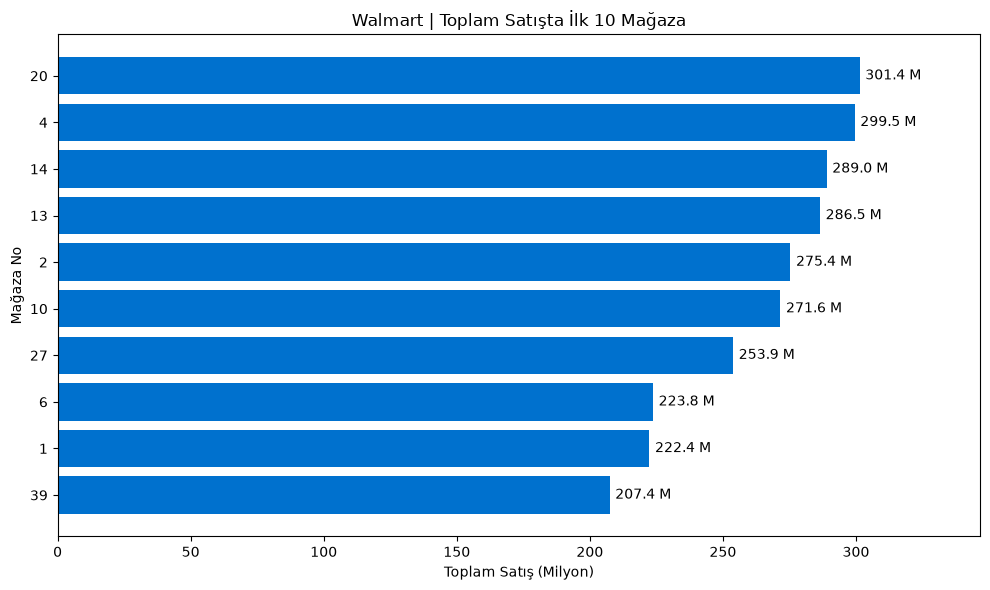

In [12]:
# Grafik alanını oluşturuyoruz: genişlik 10, yükseklik 6 inç.
fig, ax = plt.subplots(figsize=(10, 6))

# Satışları milyon birimine çeviriyoruz.
satis_milyon = ilk_10_magaza / 1_000_000

# Mağaza numaralarını metne çevirip yatay çubukları çiziyoruz.
# Metne çevirmek, numaraların kategori olarak gösterilmesini sağlar.
ax.barh(
    ilk_10_magaza.index.astype(str),
    satis_milyon,
    color="#0071CE"
)

# En yüksek satışlı mağazayı en üstte gösteriyoruz.
ax.invert_yaxis()
# Her çubuğun sonuna satış tutarını bir ondalıkla yazıyoruz.
ax.bar_label(ax.containers[0], fmt="%.1f M", padding=4)

# Etiketlerin sağ tarafta kesilmemesi için boşluk bırakıyoruz.
ax.set_xlim(0, satis_milyon.max() * 1.15)

# Başlığı ve eksen adlarını ekliyoruz.
ax.set_title("Walmart | Toplam Satışta İlk 10 Mağaza")
ax.set_xlabel("Toplam Satış (Milyon)")
ax.set_ylabel("Mağaza No")

# Yazıların grafik alanına sığmasını sağlıyoruz.
plt.tight_layout()

# Grafik çıktıları için klasör oluşturuyoruz.
from pathlib import Path
Path("grafikler").mkdir(exist_ok=True)

# Grafiği yüksek çözünürlüklü PNG olarak kaydediyoruz.
fig.savefig(
    "grafikler/ilk_10_magaza.png",
    dpi=300,
    bbox_inches="tight"
)

# Grafiği gösteriyoruz.
plt.show()

In [13]:
# Aynı tarihe ait bütün mağaza ve departman satışlarını topluyoruz.
haftalik_satis = (
    walmart.groupby("Date")["Weekly_Sales"]
    .sum()
    .sort_index()  # Tarihleri eskiden yeniye sıralıyoruz.
)

# Kaç haftalık kayıt bulunduğunu gösteriyoruz.
print("Hafta sayısı:", len(haftalik_satis))

# En yüksek satışın tarihini ve tutarını gösteriyoruz.
print("En yüksek satış haftası:", haftalik_satis.idxmax().strftime("%d.%m.%Y"))
print(f"En yüksek haftalık satış: {haftalik_satis.max():,.2f}")

Hafta sayısı: 143
En yüksek satış haftası: 24.12.2010
En yüksek haftalık satış: 80,931,415.60


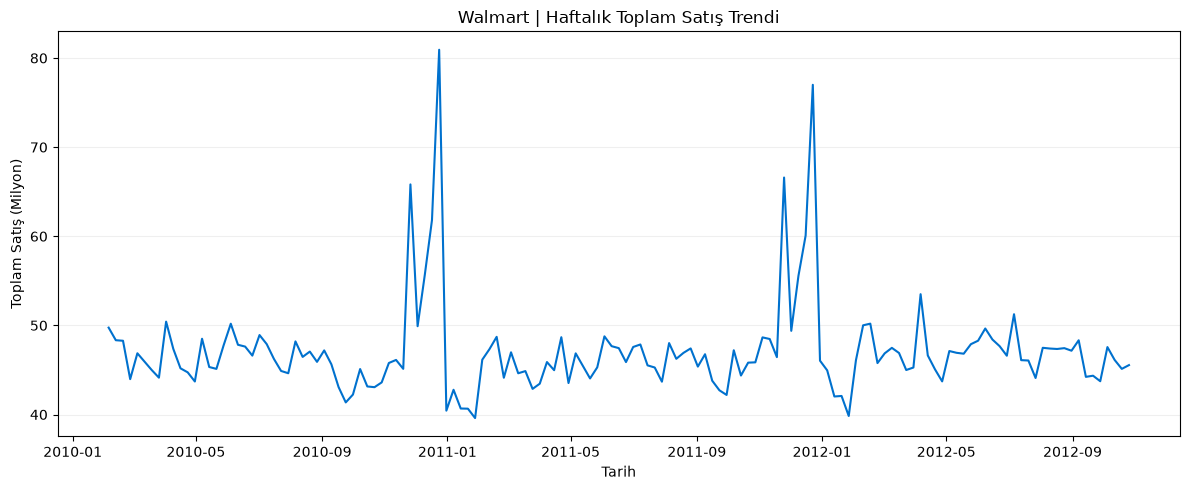

In [14]:
# Grafik alanını oluşturuyoruz.
fig, ax = plt.subplots(figsize=(12, 5))

# Haftalık satışları milyon biriminde çiziyoruz.
ax.plot(
    haftalik_satis.index,         # X ekseni: tarihler
    haftalik_satis / 1_000_000,   # Y ekseni: milyon olarak satış
    color="#0071CE",
    linewidth=1.5
)

# Başlık ve eksen adlarını ekliyoruz.
ax.set_title("Walmart | Haftalık Toplam Satış Trendi")
ax.set_xlabel("Tarih")
ax.set_ylabel("Toplam Satış (Milyon)")

# Değerlerin okunmasını kolaylaştıran yatay çizgiler ekliyoruz.
ax.grid(axis="y", alpha=0.2)

# Yerleşimi düzenleyip grafiği kaydediyoruz.
fig.tight_layout()
fig.savefig(
    "grafikler/haftalik_satis_trendi.png",
    dpi=300,
    bbox_inches="tight"
)

# Grafiği gösteriyoruz.
plt.show()

In [15]:
# Önce her haftanın bütün mağaza ve departman satışlarını topluyoruz.
haftalik_tatil = (
    walmart.groupby(["Date", "IsHoliday"], as_index=False)["Weekly_Sales"]
    .sum()
)

# Haftaları tatil durumuna göre grupluyoruz.
# Her grubun hafta sayısını ve haftalık satış ortalamasını hesaplıyoruz.
tatil_ozeti = (
    haftalik_tatil.groupby("IsHoliday")
    .agg(
        HaftaSayisi=("Weekly_Sales", "size"),
        OrtalamaHaftalikSatis=("Weekly_Sales", "mean")
    )
)

# Özet tabloyu gösteriyoruz.
tatil_ozeti

,HaftaSayisi,OrtalamaHaftalikSatis
IsHoliday,,
False,133,4.685654e+07
True,10,5.052996e+07


In [16]:
# False ve True satırlarındaki ortalama satışları seçiyoruz.
normal_ortalama = tatil_ozeti.loc[False, "OrtalamaHaftalikSatis"]
tatil_ortalama = tatil_ozeti.loc[True, "OrtalamaHaftalikSatis"]

# Normal hafta ortalamasına göre yüzde farkını hesaplıyoruz.
tatil_farki = (tatil_ortalama / normal_ortalama - 1) * 100

# Sonuçları okunaklı biçimde gösteriyoruz.
print(f"Normal hafta ortalaması: {normal_ortalama:,.2f}")
print(f"İşaretli tatil ortalaması: {tatil_ortalama:,.2f}")
print(f"Tatil farkı: %{tatil_farki:.2f}")

Normal hafta ortalaması: 46,856,537.11
İşaretli tatil ortalaması: 50,529,955.16
Tatil farkı: %7.84


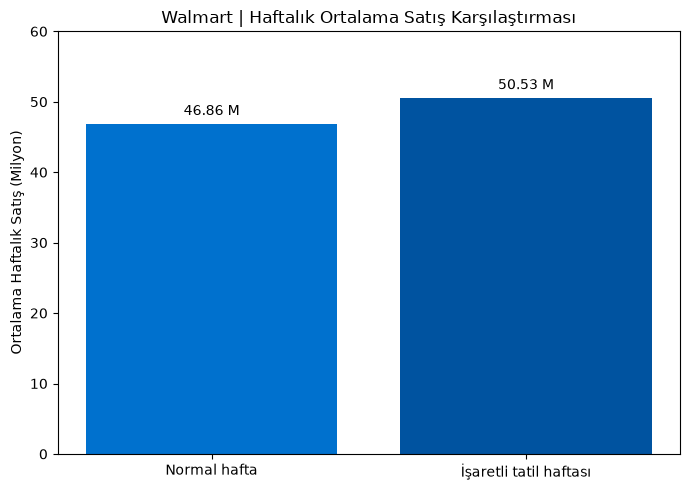

In [17]:
# Grafik alanını oluşturuyoruz.
fig, ax = plt.subplots(figsize=(7, 5))

# Haftalık ortalama satışları milyon biriminde gösteriyoruz.
cubuklar = ax.bar(
    ["Normal hafta", "İşaretli tatil haftası"],
    [normal_ortalama / 1_000_000, tatil_ortalama / 1_000_000],
    color=["#0071CE", "#0053A0"]
)

# Sütunların üzerine değer etiketlerini ekliyoruz.
ax.bar_label(cubuklar, fmt="%.2f M", padding=4)

# Başlığı ve ekseni düzenliyoruz.
ax.set_title("Walmart | Haftalık Ortalama Satış Karşılaştırması")
ax.set_ylabel("Ortalama Haftalık Satış (Milyon)")
ax.set_ylim(0, 60)  # Karşılaştırma için ekseni sıfırdan başlatıyoruz.

# Grafiği kaydedip gösteriyoruz.
fig.tight_layout()
fig.savefig(
    "grafikler/tatil_ortalama_karsilastirma.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [18]:
# Yalnızca 72 numaralı departmanın kayıtlarını seçiyoruz.
departman_72 = walmart.loc[walmart["Dept"] == 72].copy()

# Her haftanın satışını topluyor, kayıt bulunan mağazaları sayıyoruz.
departman_72_haftalik = (
    departman_72.groupby(["Date", "IsHoliday"], as_index=False)
    .agg(
        HaftalikSatis=("Weekly_Sales", "sum"),
        MagazaSayisi=("Store", "nunique")
    )
    .sort_values("Date")
)

# Yalnızca işaretli tatil haftalarını gösteriyoruz.
departman_72_haftalik.loc[
    departman_72_haftalik["IsHoliday"]
]

,Date,IsHoliday,HaftalikSatis,MagazaSayisi
1,2010-02-12,True,3102766.89,42
31,2010-09-10,True,1950600.39,43
42,2010-11-26,True,10533640.92,42
47,2010-12-31,True,2119786.56,43
53,2011-02-11,True,2889704.00,43
83,2011-09-09,True,1851735.80,41
94,2011-11-25,True,10089704.42,43
99,2011-12-30,True,2665205.18,43
105,2012-02-10,True,3234457.90,43
135,2012-09-07,True,1876003.40,42


In [19]:
# Yalnızca işaretli tatil haftalarını ayrı bir tabloya alıyoruz.
d72_tatil = departman_72_haftalik.loc[
    departman_72_haftalik["IsHoliday"]
].copy()

# Satışı en yüksek iki haftayı seçiyoruz.
zirve_iki = d72_tatil.nlargest(2, "HaftalikSatis")

# İki haftanın satışını toplam işaretli tatil satışına bölüyoruz.
zirve_pay = (
    zirve_iki["HaftalikSatis"].sum()
    / d72_tatil["HaftalikSatis"].sum()
    * 100
)

# Seçilen haftaları ve toplam paylarını gösteriyoruz.
print(zirve_iki[["Date", "HaftalikSatis"]].to_string(index=False))
print(f"\nİki haftanın tatil satışlarındaki payı: %{zirve_pay:.2f}")

      Date  HaftalikSatis
2010-11-26    10533640.92
2011-11-25    10089704.42

İki haftanın tatil satışlarındaki payı: %51.16


In [20]:
# Departman 72'nin normal haftalardaki satış ortalaması
d72_normal_ortalama = departman_72_haftalik.loc[
    ~departman_72_haftalik["IsHoliday"],
    "HaftalikSatis"
].mean()

# Bütün işaretli tatil haftalarının satış ortalaması
d72_tatil_ortalama = d72_tatil["HaftalikSatis"].mean()

# İki zirve tarihin dışındaki tatil haftalarını seçiyoruz.
d72_zirve_haric = d72_tatil.loc[
    ~d72_tatil["Date"].isin(zirve_iki["Date"])
]

# Kalan 8 tatil haftasının satış ortalaması
d72_zirve_haric_ortalama = d72_zirve_haric["HaftalikSatis"].mean()

# Her iki ortalamanın normal haftalara göre yüzde farkı
d72_tum_fark = (d72_tatil_ortalama / d72_normal_ortalama - 1) * 100
d72_zirve_haric_fark = (
    d72_zirve_haric_ortalama / d72_normal_ortalama - 1
) * 100

# Sonuçları gösteriyoruz.
print(f"Normal hafta ortalaması: {d72_normal_ortalama:,.2f}")
print(f"Tüm tatil haftaları ortalaması: {d72_tatil_ortalama:,.2f}")
print(f"İki zirve hariç ortalama: {d72_zirve_haric_ortalama:,.2f}")
print(f"\nTüm tatil haftalarının farkı: %{d72_tum_fark:.2f}")
print(f"İki zirve hariç fark: %{d72_zirve_haric_fark:.2f}")

Normal hafta ortalaması: 1,995,575.54
Tüm tatil haftaları ortalaması: 4,031,360.55
İki zirve hariç ortalama: 2,461,282.52

Tüm tatil haftalarının farkı: %102.01
İki zirve hariç fark: %23.34


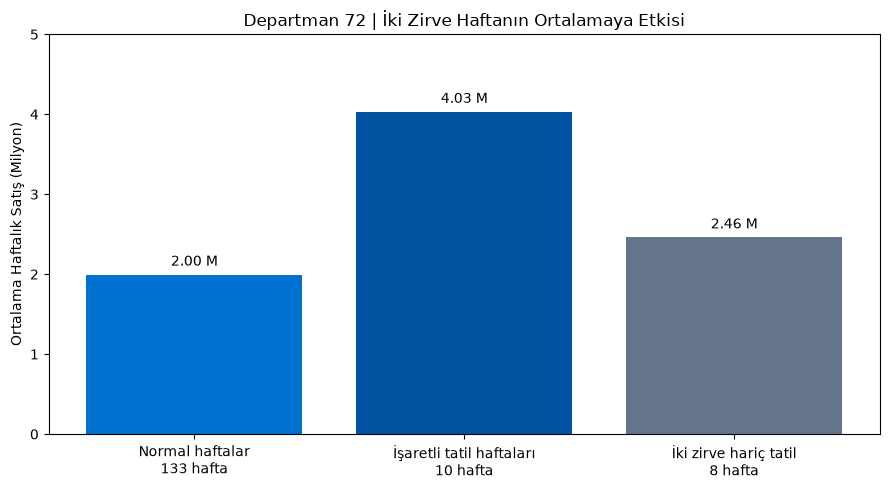

In [21]:
# Üç ortalamayı karşılaştırmak için grafik alanı oluşturuyoruz.
fig, ax = plt.subplots(figsize=(9, 5))

# Ortalamaları milyon birimine çevirip sütunları çiziyoruz.
cubuklar = ax.bar(
    ["Normal haftalar\n133 hafta",
     "İşaretli tatil haftaları\n10 hafta",
     "İki zirve hariç tatil\n8 hafta"],
    [
        d72_normal_ortalama / 1_000_000,
        d72_tatil_ortalama / 1_000_000,
        d72_zirve_haric_ortalama / 1_000_000
    ],
    color=["#0071CE", "#0053A0", "#64748B"]
)

# Sütunların üzerine ortalamaları yazıyoruz.
ax.bar_label(cubuklar, fmt="%.2f M", padding=4)

# Başlık, eksen ve etiketler için boşluk ayarlıyoruz.
ax.set_title("Departman 72 | İki Zirve Haftanın Ortalamaya Etkisi")
ax.set_ylabel("Ortalama Haftalık Satış (Milyon)")
ax.set_ylim(0, 5)

# Grafiği kaydedip gösteriyoruz.
fig.tight_layout()
fig.savefig(
    "grafikler/departman_72_zirve_karsilastirma.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Bulgular: Departman 72

- İşaretli tatil haftalarının ortalama satışı, normal haftalardan %102,01 yüksektir.
- 26 Kasım 2010 ve 25 Kasım 2011 haftaları, departmanın işaretli tatil satışlarının yaklaşık %51,16’sını oluşturur.
- Bu iki hafta karşılaştırmadan çıkarıldığında fark %23,34’e geriler.

## Yorum ve sınırlamalar

Ortalama satış farkı, iki yüksek satışlı haftadan belirgin biçimde etkilenmektedir.
Planlama yapılırken bütün tatil haftalarına tek bir ortalama uygulamak yerine
haftalar ayrı incelenmelidir.

Bu karşılaştırma nedensellik göstermez. Haftalara göre kayıt bulunan mağaza
sayısı 41–43 arasında değişmektedir. IsHoliday alanı tüm özel günleri kapsamaz.
Zirve haftalar ana veriden silinmemiş, yalnızca duyarlılık kontrolünde
hesaplama dışında tutulmuştur.

In [22]:
# Satış tutarı sıfırdan küçük olan kayıtları seçiyoruz.
negatif_satislar = walmart.loc[
    walmart["Weekly_Sales"] < 0
]

# Kaç negatif kayıt bulunduğunu ve toplam tutarını gösteriyoruz.
print("Negatif satış kaydı:", len(negatif_satislar))
print(
    f"Negatif kayıtların toplamı: "
    f"{negatif_satislar['Weekly_Sales'].sum():,.2f}"
)

# İlk 5 negatif kaydı inceliyoruz.
negatif_satislar[["Store", "Dept", "Date", "Weekly_Sales"]].head()

Negatif satış kaydı: 1285
Negatif kayıtların toplamı: -88,161.56


,Store,Dept,Date,Weekly_Sales
846,1,6,2012-08-10,-139.65
2384,1,18,2012-05-04,-1.27
6048,1,47,2010-02-19,-863.00
6049,1,47,2010-03-12,-698.00
6051,1,47,2010-10-08,-58.00


### Veri kalitesi: Negatif satış tutarları

Veride 1.285 negatif satış kaydı bulunmaktadır.
Bu kayıtların toplam tutarı −88.161,56’dır.

Negatif tutarlar iade veya muhasebe düzeltmeleriyle ilişkili olabilir;
ancak veri seti bu kayıtların nedenini açıklamamaktadır.

Bu nedenle kayıtlar silinmemiştir. SQL, Power BI ve Python
analizlerinde aynı kapsam korunarak toplam satışlara dahil edilmiştir.